---
title: "Multipoles — Level 2"
short_title: "04 Multipoles"
numbering:
  heading_2: true
  equation: true
---

# Multipoles

:::{seealso} Math for this topic
- [E-M2: Separation of variables and orthogonal functions](../math/02-separation-of-variables.ipynb)
- [M1: Vectors and ODEs](../../level2-book/math/01-vectors-odes.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 22 (dipole only) | Dipole field and torque |
| **2** | **Griffiths, ch. 3** | **Multipole expansion of V: monopole, dipole, quadrupole** |
| 3 | Jackson, ch. 4 | Spherical harmonics, tensor form of multipoles, energy in external fields |

The new skill at this level: approximating any localized charge distribution, far away, by a short series of increasingly fine terms

Math for this topic: E-M2 (Legendre polynomials) and mechanics M1 (Taylor series).
:::

Workbook example ladder: dipole in a field → quadrupole potential → nuclear quadrupole moment interaction. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad, dblquad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
eps0 = 8.854e-12          # F/m
mu0 = 4e-7 * np.pi        # H/m (to 10 significant figures)
c = 2.998e8               # m/s
k_e = 1 / (4 * np.pi * eps0)

## The Multipole Expansion

Far from a localized charge distribution, its details blur. To make that precise, expand the $1/\mathscr{r}$ in the potential integral. With $r = |\mathbf{r}|$ (field point), $r' = |\mathbf{r}'|$ (source point), $r' < r$, and $\alpha$ the angle between them, the Legendre generating function (E-M2) gives

$$
\frac{1}{\mathscr{r}} = \frac{1}{\sqrt{r^2 + r'^2 - 2rr'\cos\alpha}} = \sum_{\ell=0}^\infty\frac{r'^\ell}{r^{\ell+1}}P_\ell(\cos\alpha) .
$$

Substituting into $V = \frac{1}{4\pi\epsilon_0}\int\rho(\mathbf{r}')/\mathscr{r}\,d\tau'$:

$$
V(\mathbf{r}) = \frac{1}{4\pi\epsilon_0}\sum_{\ell=0}^\infty\frac{1}{r^{\ell+1}}\int r'^\ell P_\ell(\cos\alpha)\,\rho(\mathbf{r}')\,d\tau' .
$$ (eq-multipole)

The term with index $\ell$ falls off as $1/r^{\ell+1}$, so far away the first nonzero term dominates:

| $\ell$ | Name | Moment | Potential |
|---|---|---|---|
| 0 | monopole | $Q = \int\rho\,d\tau'$ | $\dfrac{Q}{4\pi\epsilon_0r}$ |
| 1 | dipole | $\mathbf{p} = \int\mathbf{r}'\rho\,d\tau'$ | $\dfrac{\mathbf{p}\cdot\hat{\mathbf{r}}}{4\pi\epsilon_0r^2}$ |
| 2 | quadrupole | $Q_{ij} = \int(3x_i'x_j' - r'^2\delta_{ij})\rho\,d\tau'$ | $\dfrac{1}{4\pi\epsilon_0}\dfrac{1}{2r^3}\sum_{ij}\hat r_iQ_{ij}\hat r_j$ |

The quadrupole moment is a symmetric, traceless tensor (mechanics M6): five independent numbers, which matches the five spherical harmonics with $\ell = 2$.

:::{important} Origin dependence
Only the **first nonzero** moment is independent of where the origin is put. If $Q\neq0$, shifting the origin by $\mathbf{d}$ changes $\mathbf{p}$ by $-Q\mathbf{d}$. So a neutral system has a well-defined dipole moment, but a charged one does not; choosing the origin at the "center of charge" makes $\mathbf{p} = \mathbf{0}$.
:::

In [2]:
# Moments of a set of point charges, and how fast each truncation converges
charges = np.array([1.0, -2.0, 0.6, 0.4])
pos = np.array([[0.3, 0.0, 0.5], [0.0, 0.2, 0.0], [-0.4, 0.1, -0.3], [0.1, -0.5, 0.2]])
Qtot = charges.sum()
p = (charges[:, None] * pos).sum(axis=0)
Qij = sum(q * (3 * np.outer(r_, r_) - (r_ @ r_) * np.eye(3)) for q, r_ in zip(charges, pos))
print("Q =", round(Qtot, 3), "| p =", np.round(p, 3), "| trace(Q_ij) =", round(np.trace(Qij), 12))

Q = 0.0 | p = [ 0.1  -0.54  0.4 ] | trace(Q_ij) = 0.0


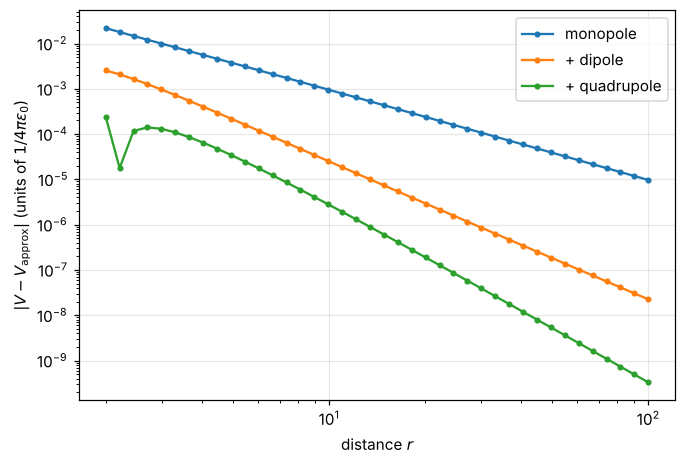

In [3]:
#| label: fig-multipole-convergence
#| caption: Error of the multipole expansion for the four charges above, along a fixed direction, keeping the monopole only, up to dipole, and up to quadrupole. Each extra term makes the error fall one power of r faster (slopes −2, −3, −4 on log axes).
def V_exact(rv):
    return sum(q / np.linalg.norm(rv - r_) for q, r_ in zip(charges, pos))
def V_multi(rv, lmax):
    r = np.linalg.norm(rv); n = rv / r
    v = Qtot / r
    if lmax >= 1: v += p @ n / r**2
    if lmax >= 2: v += 0.5 * n @ Qij @ n / r**3
    return v
direction = np.array([0.4, 0.7, 0.6]); direction /= np.linalg.norm(direction)
rs = np.logspace(0.3, 2, 40)
fig, ax = plt.subplots()
for lmax, lab in [(0, "monopole"), (1, "+ dipole"), (2, "+ quadrupole")]:
    err = [abs(V_exact(r * direction) - V_multi(r * direction, lmax)) for r in rs]
    ax.loglog(rs, err, "o-", ms=3, label=lab)
ax.set_xlabel("distance $r$"); ax.set_ylabel(r"$|V - V_{\rm approx}|$ (units of $1/4\pi\epsilon_0$)"); ax.legend()
plt.show()

### Exercises

1. Charges $+q$ at $z = d$ and $-q$ at $z = -d$. Find $Q$ and $\mathbf{p}$, and the leading far-field potential.
2. Charges $+q$, $-2q$, $+q$ at $z = d, 0, -d$ (a linear quadrupole). Show $Q = 0$ and $\mathbf{p} = \mathbf{0}$, and find $Q_{zz}$.
3. Show that $Q_{ij}$ is traceless for any distribution.

:::{dropdown} Hints
1. $\mathbf{p} = \sum q_i\mathbf{r}_i$.
2. $Q_{zz} = \sum q_i(3z_i^2 - r_i^2)$.
3. $\sum_i(3x_i'^2 - r'^2) = 3r'^2 - 3r'^2$.
:::

:::{dropdown} Answers
1. $Q = 0$, $\mathbf{p} = 2qd\,\hat{\mathbf{z}}$, $V\approx\dfrac{2qd\cos\theta}{4\pi\epsilon_0r^2}$.
2. $Q_{zz} = q(3d^2 - d^2)\cdot2 = 4qd^2$; then $V\approx\dfrac{1}{4\pi\epsilon_0}\dfrac{qd^2(3\cos^2\theta - 1)}{r^3} = \dfrac{1}{4\pi\epsilon_0}\dfrac{2qd^2P_2(\cos\theta)}{r^3}$.
3. The trace of the integrand is $3r'^2 - 3r'^2 = 0$.
:::

## The Dipole Field

For a dipole $\mathbf{p} = p\hat{\mathbf{z}}$ at the origin, $V = \dfrac{p\cos\theta}{4\pi\epsilon_0r^2}$. Taking $-\nabla V$ in spherical coordinates,

$$
\mathbf{E}_{\text{dip}} = \frac{p}{4\pi\epsilon_0r^3}\left(2\cos\theta\,\hat{\mathbf{r}} + \sin\theta\,\hat{\boldsymbol\theta}\right)
= \frac{1}{4\pi\epsilon_0r^3}\left[3(\mathbf{p}\cdot\hat{\mathbf{r}})\hat{\mathbf{r}} - \mathbf{p}\right] .
$$ (eq-dipole-field)

The coordinate-free form on the right is the one to remember. The field falls as $1/r^3$, is twice as strong along the axis as at the same distance on the equator, and points opposite to $\mathbf{p}$ on the equator.

A real dipole (two charges $\pm q$ a distance $d$ apart) matches {eq}`eq-dipole-field` only for $r\gg d$. The **ideal** or **point** dipole is the limit $d\to0$ with $p = qd$ fixed.

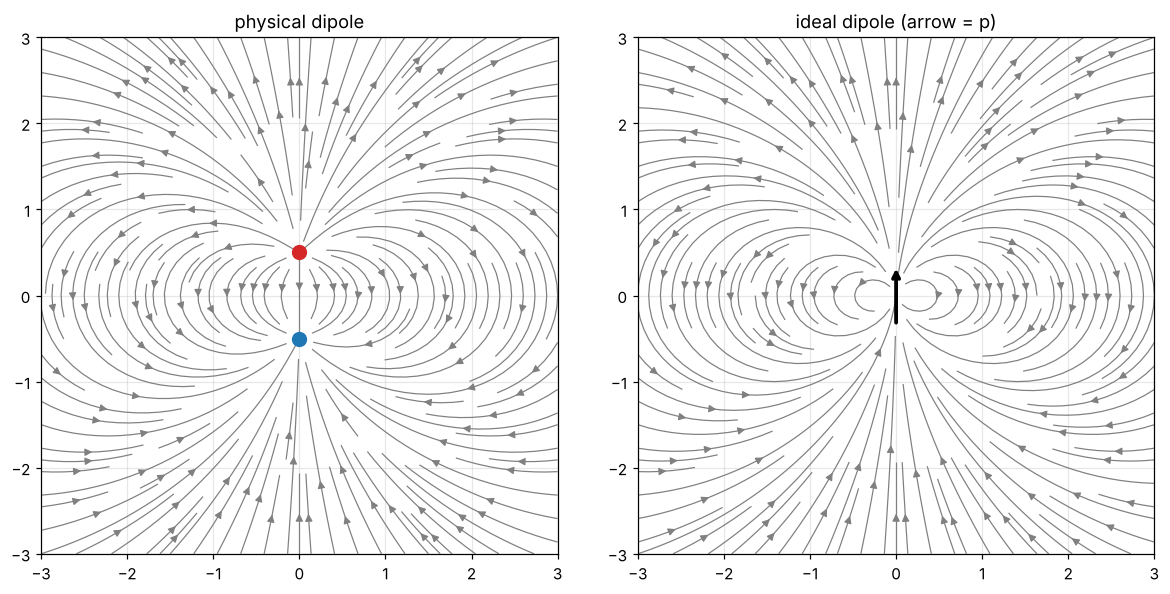

In [4]:
#| label: fig-dipole
#| caption: Field lines of a physical dipole (left, charges ±q separated by d) and of an ideal point dipole with the same p (right). Far from the charges the two pictures are identical; near them they differ completely.
x = np.linspace(-3, 3, 300); z = np.linspace(-3, 3, 300)
X, Z = np.meshgrid(x, z)
fig, axes = plt.subplots(1, 2, figsize=(11, 5.3))
d_ = 1.0
Ex = np.zeros_like(X); Ez = np.zeros_like(X)
for q_, z0 in [(1, d_ / 2), (-1, -d_ / 2)]:
    r3 = (X**2 + (Z - z0)**2)**1.5 + 1e-9
    Ex += q_ * X / r3; Ez += q_ * (Z - z0) / r3
axes[0].streamplot(X, Z, Ex, Ez, density=1.5, color="gray", linewidth=0.8)
axes[0].plot(0, d_ / 2, "o", color="tab:red", ms=9); axes[0].plot(0, -d_ / 2, "o", color="tab:blue", ms=9)
axes[0].set_title("physical dipole")
r = np.hypot(X, Z) + 1e-9
pz = 1.0
Ex2 = 3 * pz * Z * X / r**5; Ez2 = (3 * pz * Z * Z / r**2 - pz) / r**3
axes[1].streamplot(X, Z, Ex2, Ez2, density=1.5, color="gray", linewidth=0.8)
axes[1].annotate("", xy=(0, 0.35), xytext=(0, -0.35), arrowprops=dict(arrowstyle="->", color="k", lw=2.5))
axes[1].set_title("ideal dipole (arrow = p)")
for ax in axes: ax.set_aspect("equal")
plt.tight_layout(); plt.show()

In [5]:
# Derive eq-dipole-field from V
r, th, p, e0 = sp.symbols("r theta p epsilon_0", positive=True)
V = p * sp.cos(th) / (4 * sp.pi * e0 * r**2)
print("E_r     =", sp.simplify(-sp.diff(V, r)))
print("E_theta =", sp.simplify(-sp.diff(V, th) / r))

E_r     = p*cos(theta)/(2*pi*epsilon_0*r**3)
E_theta = p*sin(theta)/(4*pi*epsilon_0*r**3)


## Dipoles in External Fields

A dipole in a field $\mathbf{E}$ (from other sources) experiences

$$
\boldsymbol\tau = \mathbf{p}\times\mathbf{E}, \qquad U = -\mathbf{p}\cdot\mathbf{E}, \qquad \mathbf{F} = \nabla(\mathbf{p}\cdot\mathbf{E}) = (\mathbf{p}\cdot\nabla)\mathbf{E} \ \ (\text{for fixed }\mathbf{p}) .
$$ (eq-dipole-in-field)

The torque aligns $\mathbf{p}$ with $\mathbf{E}$ (minimum energy), and a net force appears only if the field is **nonuniform**, pulling the aligned dipole toward stronger field. This is why a charged comb picks up neutral bits of paper: it induces dipoles in them and then pulls on those dipoles in its nonuniform field.

The next term, the quadrupole, interacts with field **gradients**: $U = -\tfrac16\sum_{ij}Q_{ij}\,\partial_iE_j$. Atomic nuclei have no electric dipole moment but many have quadrupole moments, and the resulting energy shifts in the gradient of the electrons' field are measured precisely in nuclear quadrupole resonance (the Level 3 rung of this topic).

### Exercises

1. A water molecule has $p\approx6.2\times10^{-30}$ C·m. Find the energy difference between aligned and anti-aligned orientations in a field of $10^6$ V/m, and compare with $k_BT$ at room temperature ($4.1\times10^{-21}$ J).
2. A dipole $\mathbf{p}$ sits a distance $r$ from a point charge $q$, pointing directly away from it. Find the force on the dipole.
3. Show that the interaction energy of two dipoles is $U = \dfrac{1}{4\pi\epsilon_0r^3}\left[\mathbf{p}_1\cdot\mathbf{p}_2 - 3(\mathbf{p}_1\cdot\hat{\mathbf{r}})(\mathbf{p}_2\cdot\hat{\mathbf{r}})\right]$.

:::{dropdown} Hints
1. $\Delta U = 2pE$.
2. Use $\mathbf{F} = (\mathbf{p}\cdot\nabla)\mathbf{E}$ with $E = q/(4\pi\epsilon_0r^2)$ along $\hat{\mathbf{r}}$.
3. $U = -\mathbf{p}_2\cdot\mathbf{E}_1$ with $\mathbf{E}_1$ from {eq}`eq-dipole-field`.
:::

:::{dropdown} Answers
1. $\Delta U = 2(6.2\times10^{-30})(10^6)\approx1.2\times10^{-23}$ J, about $0.3\%$ of $k_BT$: thermal motion wins, so alignment is weak.
2. $F = p\,\dfrac{d}{dr}\dfrac{q}{4\pi\epsilon_0r^2} = -\dfrac{2pq}{4\pi\epsilon_0r^3}$, an attraction toward $q$ (for $q > 0$).
3. Substituting gives the stated result directly.
:::

## Summary

- Expanding $1/\mathscr{r}$ in Legendre polynomials gives $V$ as a series in $1/r^{\ell+1}$ with moments $Q$, $\mathbf{p}$, $Q_{ij}$, ....
- Far away, the first nonzero moment dominates, and only it is independent of the origin.
- The dipole field is $\frac{1}{4\pi\epsilon_0r^3}[3(\mathbf{p}\cdot\hat{\mathbf{r}})\hat{\mathbf{r}} - \mathbf{p}]$; physical and ideal dipoles agree only far away.
- In an external field a dipole feels torque $\mathbf{p}\times\mathbf{E}$, energy $-\mathbf{p}\cdot\mathbf{E}$, and a force only in a nonuniform field; quadrupoles couple to field gradients.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.